### **Our own tempo estimator**

The blocks below show how we built our own tempo estimator using songs from
the development set. We use the original audio and compare Fourier,
autocorrelation and a combination of the two.

First we go through one excerpt step by step, then try three examples.
After that we run all three methods on all 140 development excerpts to see how
they work across the different dance styles.

The final comparison between original and instrumental audio will be in
another notebook using the test set.

In [1]:
# Libraries
import csv
from collections import Counter

import matplotlib.pyplot as plt
import numpy as np
import soundfile as sf
from IPython.display import Markdown, display

# Function imports
from ballroom_dataset import PROJECT_ROOT, get_development_set
from tempo_estimator import (
    compute_stft, log_compression,
    spectral_novelty_function, enhanced_novelty_function,
    fourier_tempogram, autocorrelation_tempogram, global_tempo_estimation,
    combined_tempo_estimation, estimate_tempo,
)

# The following makes the plot look nice
params = {'legend.fontsize': 'x-large',
    'figure.figsize': (10, 5),
    'axes.labelsize': 'x-large',
    'axes.titlesize':'x-large',
    'xtick.labelsize':'x-large',
    'ytick.labelsize':'x-large'}
plt.rcParams.update(params)

### **Parameters**

These are the values we use for all three methods. Window and hop sizes are in
seconds. We keep the same values for all songs.

In [2]:
# About 46 ms and 12 ms: 2048-sample windows with 75% overlap at 44,100 Hz.
# These gave lower mean BPM error than 0.05/0.01 on the development set.
window_size = 0.04644
hop_size = 0.01161
gamma = 100
local_average_size = 0.1
tempogram_window_size = 5
tempogram_hop_size = 0.1
bpm_min = 30
bpm_max = 300

bpms = np.arange(bpm_min, bpm_max + 1)

parameters = {
    "window_size": window_size,
    "hop_size": hop_size,
    "gamma": gamma,
    "local_average_size": local_average_size,
    "tempogram_window_size": tempogram_window_size,
    "tempogram_hop_size": tempogram_hop_size,
    "bpm_min": bpm_min,
    "bpm_max": bpm_max,
}

### **Loading one file from the development set**

In [3]:
development_set = get_development_set()
excerpt = next(track for track in development_set if track.track_id == "Albums-AnaBelen_Veneo-03")

print("The file path of the excerpt:")
print(excerpt.original_path)

print("The dance style of the excerpt:")
print(excerpt.dance_style)

print("The BPM for the excerpt:")
print(excerpt.reference_bpm)

The file path of the excerpt:
/Users/carlkjellman/Projects/MusicInformatics/DT2470-G6-Project/data/ballroom/B_1.0/audio/Rumba-International/Albums-AnaBelen_Veneo-03.wav
The dance style of the excerpt:
rumba
The BPM for the excerpt:
122.0


### **Opening the file with soundfile so we can work with it**

We read the audio and use the sample rate from the file.

Sample rate: 44100
Duration of excerpt (s): 30.05


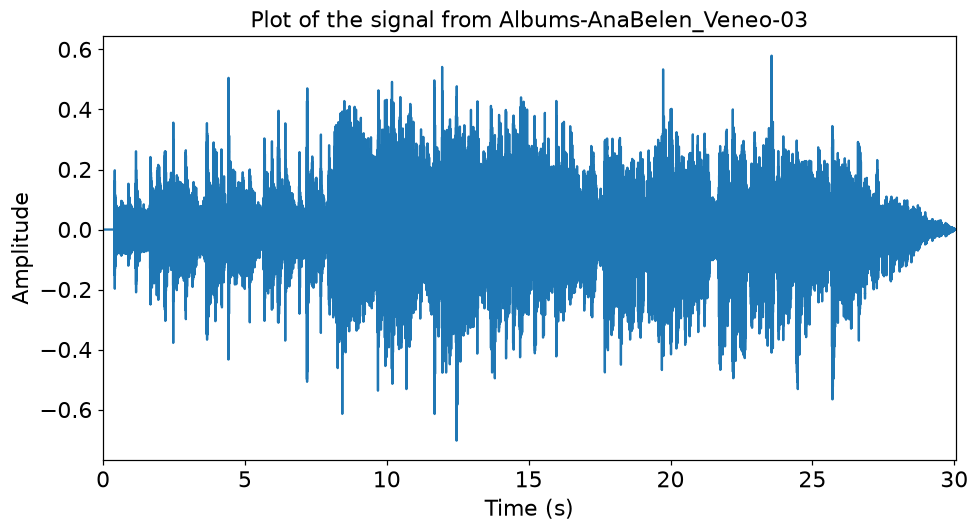

In [4]:
data, sample_rate = sf.read(excerpt.original_path)

time = np.arange(data.size) / sample_rate
duration_seconds = len(data) / sample_rate

print(f"Sample rate: {sample_rate}")
print(f"Duration of excerpt (s): {duration_seconds:.2f}")

# Plot the signal
plt.plot(time, data)
plt.xlabel("Time (s)")
plt.xlim(0, duration_seconds)
plt.ylabel("Amplitude")
plt.title(f"Plot of the signal from {excerpt.track_id}")
plt.show()

### **Now we compute the STFT of the signal**

This shows how the frequencies change over time. We convert the window
and hop sizes from seconds to samples using the file's sample rate.

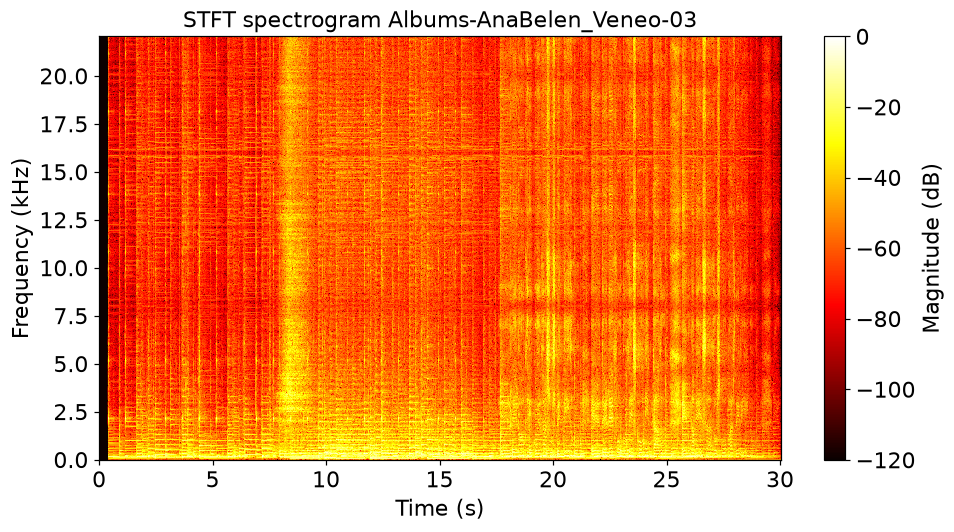

In [5]:
freq_excerpt, times_excerpt, stft_excerpt = compute_stft(
    data, sample_rate, window_size, hop_size
)

hop_samples = round(hop_size * sample_rate)
novelty_rate = sample_rate / hop_samples

# Convert to db scale
abs_stft_excerpt = np.abs(stft_excerpt)
db_stft_excerpt = 20 * np.log10(np.maximum(abs_stft_excerpt /abs_stft_excerpt.max(), 1e-6))

khz_freq_excerpt = freq_excerpt / 1000


plt.pcolormesh(times_excerpt, khz_freq_excerpt,db_stft_excerpt,cmap="hot", vmin=-120, vmax=0, shading="auto")
plt.xlabel("Time (s)")
plt.ylabel("Frequency (kHz)")
plt.xlim(0,duration_seconds)
plt.colorbar(label="Magnitude (dB)")
plt.title(f"STFT spectrogram {excerpt.track_id}")
plt.show()

### **Logarithmic compression**

Now we apply logarithmic compression to obtain the compressed spectrogram.
In the book this is given by equation 6.5:

$$
\mathcal{Y} := \Gamma_{\gamma}(|\mathcal{X}|) = \log(1 + \gamma \cdot |\mathcal{X}|)
$$

We use $\gamma = 100$, following the spectral novelty example accompanying
the book. Compression makes weaker spectral components more visible.

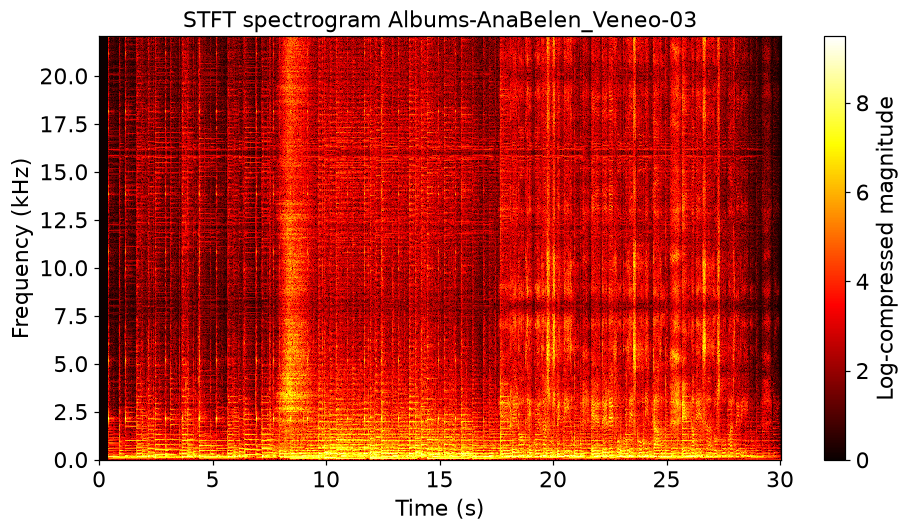

In [6]:
log_compressed_excerpt = log_compression(stft_excerpt, gamma)

plt.pcolormesh(
    times_excerpt,
    khz_freq_excerpt,
    log_compressed_excerpt,
    cmap="hot",
    shading="auto",
)
plt.xlabel("Time (s)")
plt.ylabel("Frequency (kHz)")
plt.xlim(0, duration_seconds)
plt.colorbar(label="Log-compressed magnitude")
plt.title(f"STFT spectrogram {excerpt.track_id}")
plt.show()

### **Spectral-based novelty function**

Now we get the spectral-based novelty function using equation 6.6:

$$
\Delta_{\mathrm{Spectral}}(n) := \sum_{k=0}^{K} \left| \mathcal{Y}(n+1,k) - \mathcal{Y}(n,k) \right|_{\geq 0}
$$

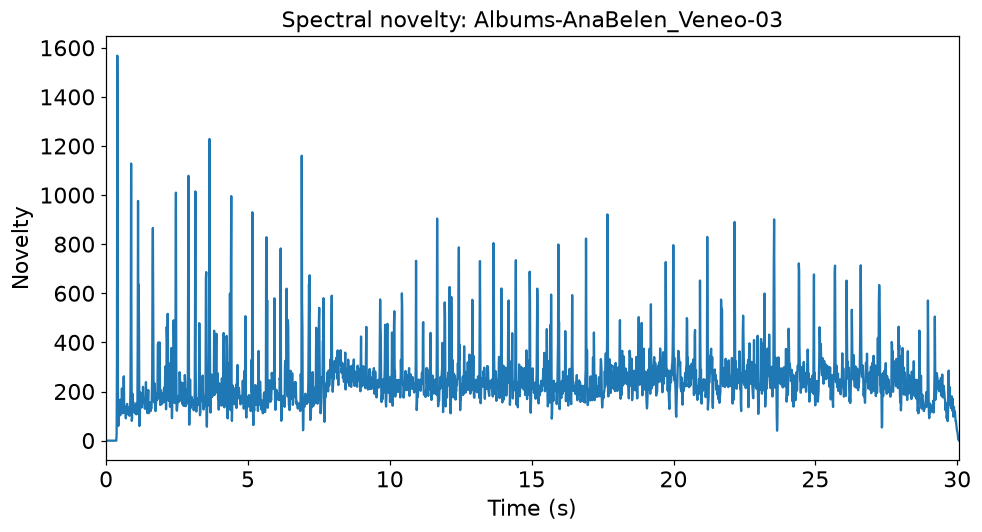

In [7]:
spectral_novelty = spectral_novelty_function(log_compressed_excerpt)

plt.plot(times_excerpt[1:], spectral_novelty)
plt.xlabel("Time (s)")
plt.ylabel("Novelty")
plt.xlim(0, duration_seconds)
plt.title(f"Spectral novelty: {excerpt.track_id}")
plt.show()

### **Enhanced novelty function**

The book uses equation 6.7 (local average function) to build the enhanced novelty function 6.8

Equation 6.7:
$$
\mu(n) := \frac{1}{2M+1} \sum_{m=-M}^{M} \Delta_{\mathrm{Spectral}}(n+m)
$$

Equation 6.8:
$$
\bar{\Delta}_{\mathrm{Spectral}}(n) := \left| \Delta_{\mathrm{Spectral}}(n) - \mu(n) \right|_{\geq 0}
$$

Here, $M$ is the number of novelty frames on each side. We set the width in
seconds and convert it using the sampling rate of our novelty curve.

We use 0.1 seconds on each side, so the full averaging window is about
0.2 seconds. We round up to a whole number of novelty frames.

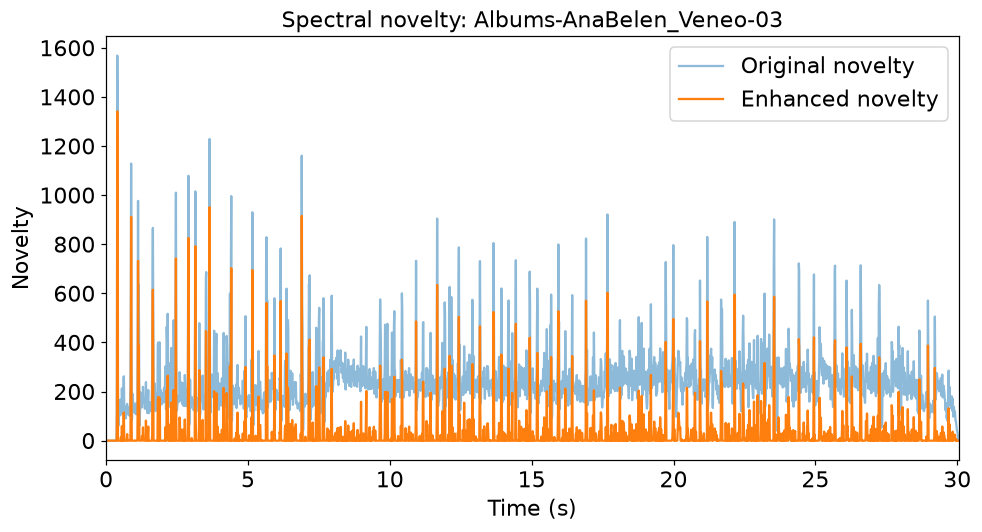

In [8]:
M = int(np.ceil(local_average_size * novelty_rate))
enhanced_novelty = enhanced_novelty_function(spectral_novelty, M)

plt.plot(times_excerpt[1:], spectral_novelty,
         label="Original novelty", alpha=0.5)
plt.plot(times_excerpt[1:], enhanced_novelty,
         label="Enhanced novelty")

plt.xlabel("Time (s)")
plt.ylabel("Novelty")
plt.xlim(0, duration_seconds)
plt.title(f"Spectral novelty: {excerpt.track_id}")
plt.legend()
plt.show()

### **Fourier tempogram**

Following section 6.2.2 in the book, we use equation 6.25:

$$
\mathcal{F}(n,\omega) :=
\widetilde{\Delta}^{w}(n,\omega) =
\sum_{m \in \mathbb{Z}}
\Delta(m)\,\overline{w}(m-n)\exp(-2\pi i\omega m)
$$

Here we have that:

- $\Delta(m)$ is our enhanced novelty curve at frame $m$.
- $n$ is the frame where the analysis window is centered.
- $w(m-n)$ is a Hann window centered at $n$. The bar means complex conjugation, which does not change our real-valued Hann window.
- $\omega$ is the frequency we want to analyse, measured in cycles per novelty frame.
- $\exp(-2\pi i\omega m)$ is a complex sinusoid representing that frequency.

The idea is to compare a section of the novelty curve with different rhythmic
periodicities. A strong match gives a large Fourier coefficient magnitude.

For each candidate tempo $\tau$ in BPM, we calculate the frequency used in our code:

$$
\omega = \frac{\tau}{60F_\Delta}
$$

Here, $F_\Delta$ is the sampling rate of the novelty curve, measured in frames
per second.

We repeat this calculation across time and candidate tempos. Taking the absolute
value of each complex Fourier coefficient gives us the Fourier tempogram.
This last magnitude step follows equation 6.26.


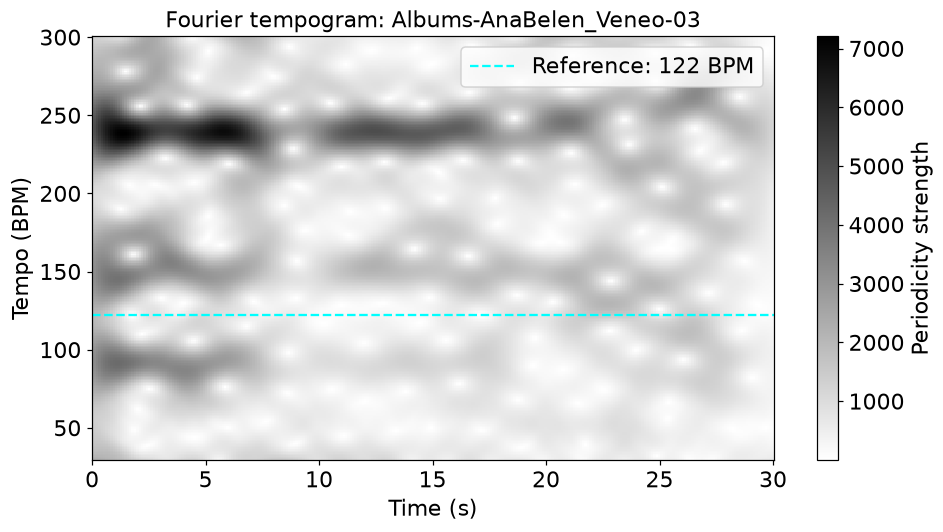

In [9]:
tempogram, tempogram_times = fourier_tempogram(
    enhanced_novelty,
    novelty_rate,
    bpms,
    window_seconds=tempogram_window_size,
    hop_seconds=tempogram_hop_size,
)

# Align with our novelty curve's first time point.
tempogram_times = tempogram_times + times_excerpt[1]

plt.pcolormesh(
    tempogram_times,
    bpms,
    tempogram,
    shading="auto",
    cmap="gray_r",
)
plt.xlabel("Time (s)")
plt.ylabel("Tempo (BPM)")
plt.xlim(0, duration_seconds)
plt.colorbar(label="Periodicity strength")
plt.title(f"Fourier tempogram: {excerpt.track_id}")
plt.axhline(
    y=excerpt.reference_bpm,
    color="cyan",
    linestyle="--",
    label=f"Reference: {excerpt.reference_bpm:g} BPM",
)
plt.legend()
plt.show()

### **Autocorrelation tempogram**

Now we will try the autocorrelation approach from section 6.2.3 in the book.
The idea is to compare a section of our novelty curve with a shifted copy of
itself. If the peaks line up, we get a strong response for that shift.

First we apply a window to the enhanced novelty curve:

$$
\Delta_{w,n}(m) := \bar{\Delta}_{\mathrm{Spectral}}(m)\,w(m-n)
$$

We then calculate the autocorrelation:

$$
\mathcal{A}(n,\ell) :=
\sum_{m \in \mathbb{Z}} \Delta_{w,n}(m)\,\Delta_{w,n}(m-\ell)
$$

Here we have that:

- $n$ is the position where the window is centered.
- $m$ goes through the novelty frames.
- $\ell$ is the shift, also called the lag, measured in novelty frames.
- $w$ is our window. We use the same Hann window as in the Fourier version.

A shift of $\ell$ frames corresponds to $\ell/F_\Delta$ seconds. We convert
between lag and tempo using:

$$
\tau = \frac{60F_\Delta}{\ell}
\qquad\Longleftrightarrow\qquad
\ell = \frac{60F_\Delta}{\tau}
$$

For each candidate BPM, we look up the autocorrelation strength at its lag.
We use interpolation because a candidate tempo can fall between two integer
lags. This gives us a tempogram with the same BPM axis as the Fourier version.
Here we use the raw autocorrelation, without an extra lag-normalization step.


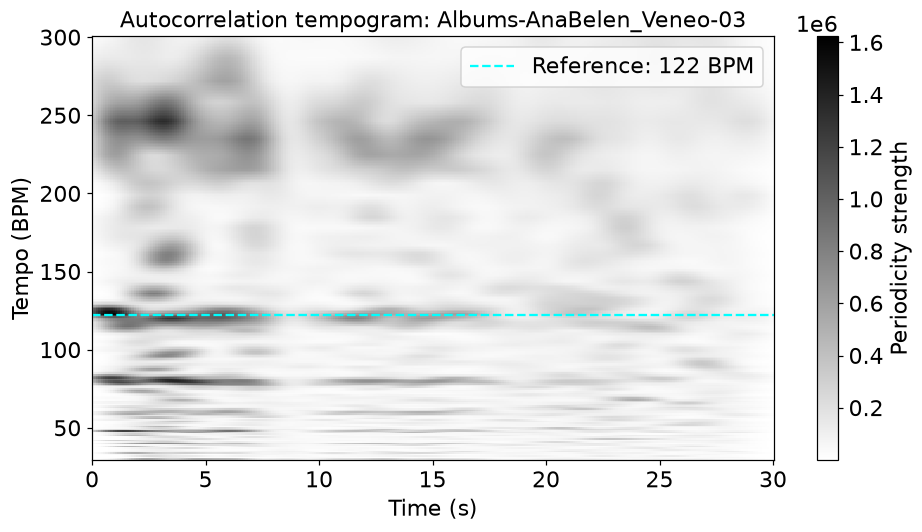

In [10]:
autocorr_tempogram, autocorr_times = autocorrelation_tempogram(
    enhanced_novelty,
    novelty_rate,
    bpms,
    window_seconds=tempogram_window_size,
    hop_seconds=tempogram_hop_size,
)

# Align with our novelty curve's first time point.
autocorr_times = autocorr_times + times_excerpt[1]

plt.pcolormesh(
    autocorr_times,
    bpms,
    autocorr_tempogram,
    shading="auto",
    cmap="gray_r",
)
plt.xlabel("Time (s)")
plt.ylabel("Tempo (BPM)")
plt.xlim(0, duration_seconds)
plt.colorbar(label="Periodicity strength")
plt.title(f"Autocorrelation tempogram: {excerpt.track_id}")
plt.axhline(
    y=excerpt.reference_bpm,
    color="cyan",
    linestyle="--",
    label=f"Reference: {excerpt.reference_bpm:g} BPM",
)
plt.legend()
plt.show()

### **Global tempo estimation**

Both tempograms show the strength of different tempos over time.
We now want one estimated tempo for the whole excerpt. For this first
approach, we assume that the tempo stays roughly constant.

Following section 6.2.3 in the book, we use equation 6.32 to average the
tempogram strengths across time:

$$
\mathcal{T}_{\mathrm{Average}}(\tau)
:=
\frac{1}{N}\sum_{n=1}^{N}\mathcal{T}(n,\tau)
$$

Here we have that:

- $\tau$ is a candidate tempo in BPM.
- $N$ is the number of time frames in the tempogram.
- $\mathcal{T}(n,\tau)$ is the tempogram strength at
  time frame $n$ and candidate tempo $\tau$.

Averaging combines the local periodicity evidence into one strength value
for each candidate tempo. Although this approach is discussed in the
autocorrelation section, we use the same calculation for both tempograms.

Following the maximum-selection approach described around equation 6.33,
we choose the candidate tempo with the highest average strength:

$$
\hat{\tau}
=
\operatorname*{arg\,max}_{\tau \in \Theta}
\mathcal{T}_{\mathrm{Average}}(\tau)
$$

Here, $\Theta$ is our set of candidate BPM values. We write this selection
using argmax because we want the BPM corresponding to the maximum,
rather than the maximum strength itself.

Finally, we evaluate our estimate using absolute tempo error:

$$
e = |\hat{\tau} - \tau_{\mathrm{reference}}|
$$

This last equation is our chosen evaluation metric. The error is measured
in BPM, where a smaller value means a closer estimate. The reference tempo
is only used for evaluation and does not influence the estimated tempo.

In [11]:
fourier_bpm, fourier_strength = global_tempo_estimation(tempogram, bpms)
autocorr_bpm, autocorr_strength = global_tempo_estimation(autocorr_tempogram, bpms)

# The reference tempo is only used to evaluate our estimates.
reference_bpm = excerpt.reference_bpm
fourier_error = abs(fourier_bpm - reference_bpm)
autocorr_error = abs(autocorr_bpm - reference_bpm)

print(f"Reference tempo: {reference_bpm:.1f} BPM")
print(f"Fourier estimate: {fourier_bpm:.1f} BPM, absolute error: {fourier_error:.1f} BPM")
print(f"Autocorrelation estimate: {autocorr_bpm:.1f} BPM, absolute error: {autocorr_error:.1f} BPM")


Reference tempo: 122.0 BPM
Fourier estimate: 240.0 BPM, absolute error: 118.0 BPM
Autocorrelation estimate: 80.0 BPM, absolute error: 42.0 BPM


### **Combining Fourier and autocorrelation**

The book suggests combining the two methods to help with half and double
tempo errors. Here we combine their global strength curves, after averaging
each tempogram across time.

We divide each curve by its maximum and multiply them together:

$$
S_{\mathrm{Combined}}(\tau) =
\frac{S_{\mathrm{Fourier}}(\tau)}{\max_{\theta \in \Theta} S_{\mathrm{Fourier}}(\theta)}
\cdot
\frac{S_{\mathrm{Autocorrelation}}(\tau)}{\max_{\theta \in \Theta} S_{\mathrm{Autocorrelation}}(\theta)}
$$

Here, $S$ is a global strength curve and $\Theta$ is our set of candidate
tempos. We select the BPM with the highest combined strength.

Multiplication is our choice for combining the methods. It gives a strong
response where both methods support a tempo, but they can still agree on
the wrong beat level. We check whether it helps using the same evaluation
as for the individual methods.


In [12]:
combined_bpm, combined_strength = combined_tempo_estimation(
    fourier_strength, autocorr_strength, bpms
)
combined_error = abs(combined_bpm - reference_bpm)

print(f"Combined estimate: {combined_bpm:.1f} BPM, absolute error: {combined_error:.1f} BPM")


Combined estimate: 240.0 BPM, absolute error: 118.0 BPM


### **Comparing the three methods**

Now we plot the three strength curves to see which tempos they pick up.
We divide each curve by its maximum for the plot, so we can compare their
shapes. This does not change which BPM each method selects.


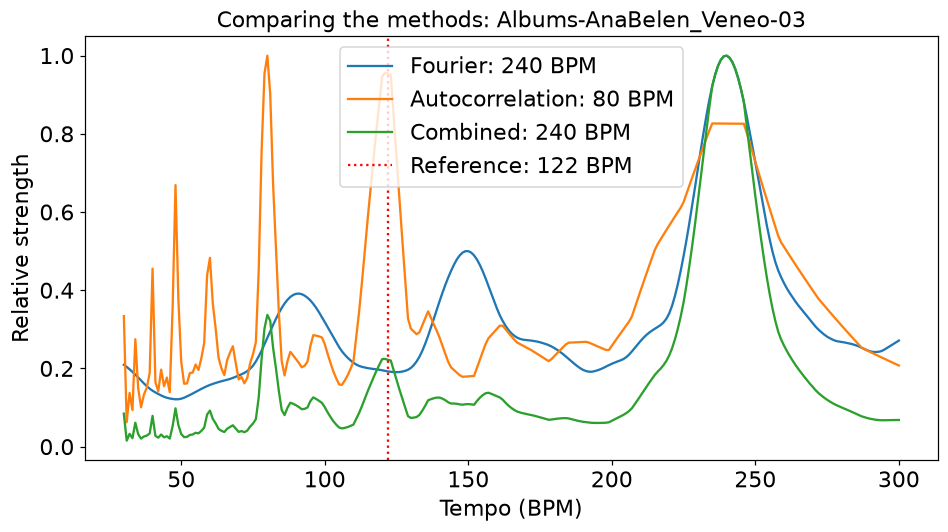

In [13]:
plt.plot(
    bpms,
    fourier_strength / fourier_strength.max(),
    label=f"Fourier: {fourier_bpm:g} BPM",
)
plt.plot(
    bpms,
    autocorr_strength / autocorr_strength.max(),
    label=f"Autocorrelation: {autocorr_bpm:g} BPM",
)
plt.plot(
    bpms,
    combined_strength / combined_strength.max(),
    label=f"Combined: {combined_bpm:g} BPM",
)
plt.axvline(
    excerpt.reference_bpm,
    color="red",
    linestyle=":",
    label=f"Reference: {excerpt.reference_bpm:g} BPM",
)

plt.xlabel("Tempo (BPM)")
plt.ylabel("Relative strength")
plt.title(f"Comparing the methods: {excerpt.track_id}")
plt.legend()
plt.show()


### **Half and double tempo**

Sometimes we find a repeating pulse but select the wrong beat level.
For example, an estimate of 240 BPM is double a reference tempo of 120 BPM.

We use four categories to describe the estimates:

- **Correct:** within 4% of the reference tempo.
- **Half:** within 4% of half the reference tempo.
- **Double:** within 4% of double the reference tempo.
- **Other:** none of the above.

For each target tempo $\tau_{\mathrm{target}}$, we check:

$$
|\hat{\tau} - \tau_{\mathrm{target}}| \leq 0.04\,\tau_{\mathrm{target}}
$$

This is how we evaluate the results. It does not change the estimated BPM.
We also report accuracy when half and double estimates are accepted,
alongside the strict accuracy that only accepts the correct category.

In [14]:
tolerance = 0.04

def tempo_category(estimated_bpm, reference_bpm):
    for category, factor in [("Correct", 1), ("Half", 0.5), ("Double", 2)]:
        target_bpm = reference_bpm * factor
        if abs(estimated_bpm - target_bpm) <= tolerance * target_bpm:
            return category
    return "Other"

### **Trying three development excerpts**

We keep the rumba excerpt from above and add the quickstep and cha-cha-cha
excerpts from our earlier examples. These show how the methods behave on
different songs. We use the original audio for all three.

The plots also mark half and double the reference tempo. The table labels
each estimate using the categories above. These reference lines and labels
are only used to explain the results after estimating the tempo.
Only reference lines inside our 30 to 300 BPM range are shown.

In [15]:
def compare_estimators(data: np.ndarray, sample_rate: int):
    fourier_bpm, fourier_strength = estimate_tempo(
        data, sample_rate, parameters, "fourier"
    )
    autocorr_bpm, autocorr_strength = estimate_tempo(
        data, sample_rate, parameters, "autocorr"
    )

    combined_bpm, combined_strength = combined_tempo_estimation(
        fourier_strength, autocorr_strength, bpms
    )

    return [
        ("Fourier", fourier_bpm, fourier_strength),
        ("Autocorrelation", autocorr_bpm, autocorr_strength),
        ("Combined", combined_bpm, combined_strength),
    ]


methods = ["Fourier", "Autocorrelation", "Combined"]


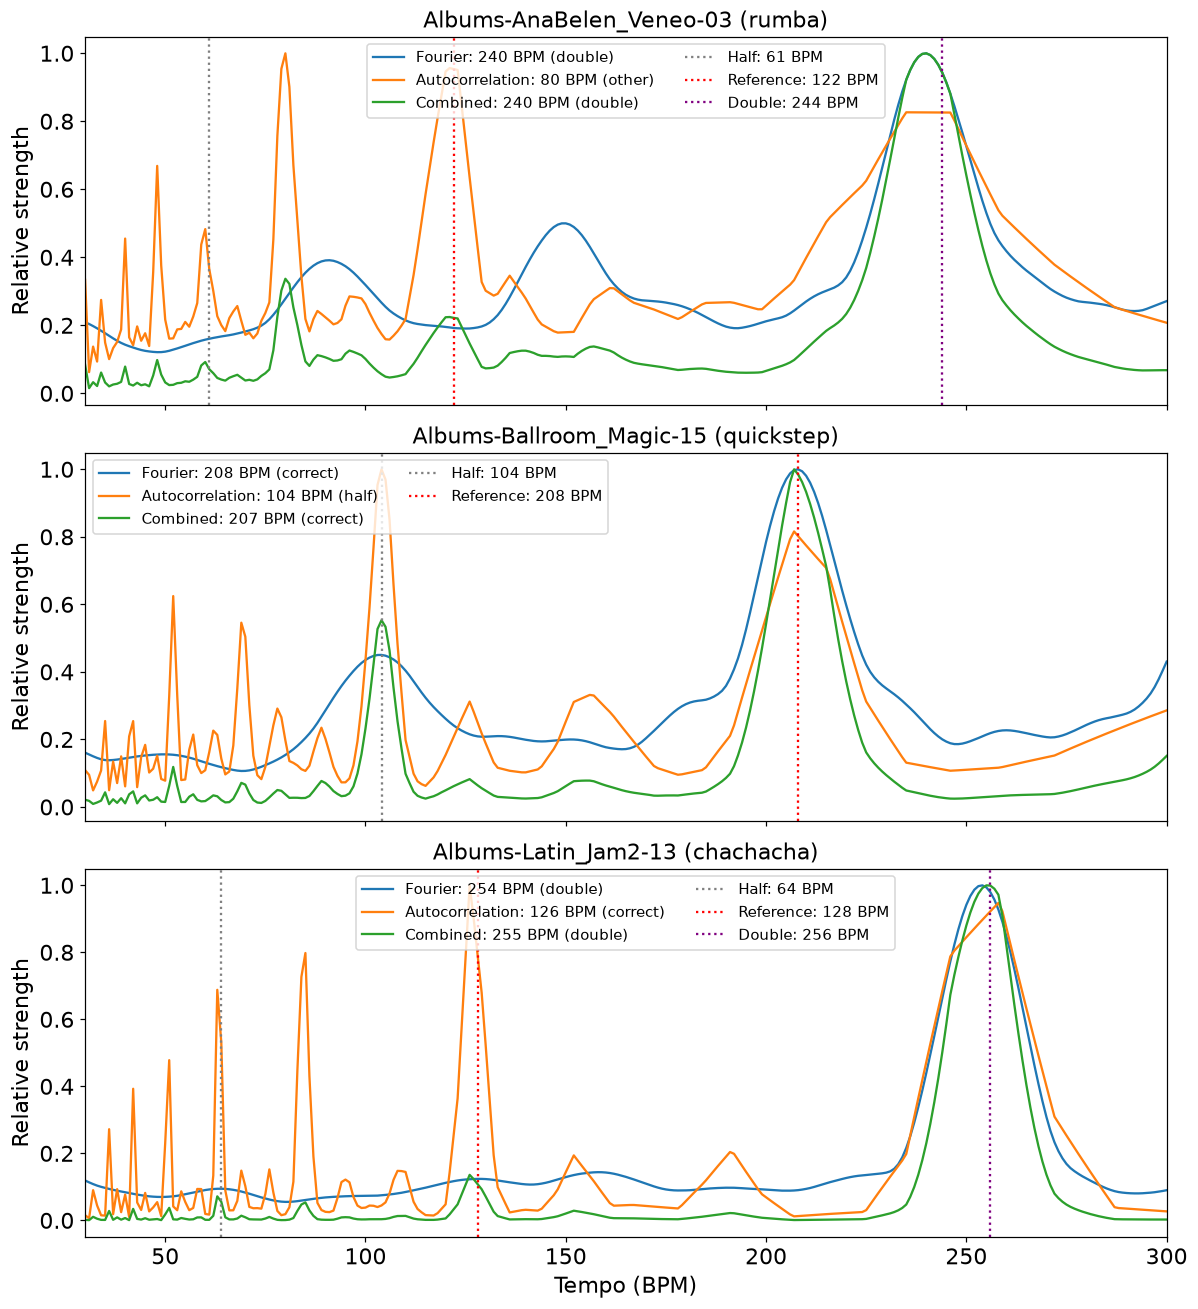

| Excerpt | Method | Reference BPM | Estimated BPM | Absolute error | Result |
| --- | --- | ---: | ---: | ---: | --- |
| Albums-AnaBelen_Veneo-03 | Fourier | 122.0 | 240.0 | 118.0 | Double |
| Albums-AnaBelen_Veneo-03 | Autocorrelation | 122.0 | 80.0 | 42.0 | Other |
| Albums-AnaBelen_Veneo-03 | Combined | 122.0 | 240.0 | 118.0 | Double |
| Albums-Ballroom_Magic-15 | Fourier | 208.0 | 208.0 | 0.0 | Correct |
| Albums-Ballroom_Magic-15 | Autocorrelation | 208.0 | 104.0 | 104.0 | Half |
| Albums-Ballroom_Magic-15 | Combined | 208.0 | 207.0 | 1.0 | Correct |
| Albums-Latin_Jam2-13 | Fourier | 128.0 | 254.0 | 126.0 | Double |
| Albums-Latin_Jam2-13 | Autocorrelation | 128.0 | 126.0 | 2.0 | Correct |
| Albums-Latin_Jam2-13 | Combined | 128.0 | 255.0 | 127.0 | Double |


In [16]:
example_ids = [
    "Albums-AnaBelen_Veneo-03",
    "Albums-Ballroom_Magic-15",
    "Albums-Latin_Jam2-13",
]
examples = [next(track for track in development_set if track.track_id == track_id)
            for track_id in example_ids]

comparison_results = []
fig, axes = plt.subplots(3, 1, figsize=(11, 12), sharex=True)

for example, ax in zip(examples, axes):
    example_data, example_sample_rate = sf.read(example.original_path)
    for method, estimated_bpm, strength in compare_estimators(
        example_data, example_sample_rate
    ):
        category = tempo_category(estimated_bpm, example.reference_bpm)
        comparison_results.append({
            "track_id": example.track_id,
            "method": method,
            "reference_bpm": example.reference_bpm,
            "estimated_bpm": estimated_bpm,
            "absolute_error": abs(estimated_bpm - example.reference_bpm),
            "category": category,
        })
        ax.plot(bpms, strength / strength.max(),
                label=f"{method}: {estimated_bpm:g} BPM ({category.lower()})")

    for factor, label, color in [
        (0.5, "Half", "gray"),
        (1, "Reference", "red"),
        (2, "Double", "purple"),
    ]:
        reference_line = factor * example.reference_bpm
        if bpms[0] <= reference_line <= bpms[-1]:
            ax.axvline(reference_line, color=color, linestyle=":",
                       label=f"{label}: {reference_line:g} BPM")

    ax.set_xlim(bpms[0], bpms[-1])
    ax.set_ylabel("Relative strength")
    ax.set_title(f"{example.track_id} ({example.dance_style})")
    ax.legend(fontsize=10, ncol=2)

axes[-1].set_xlabel("Tempo (BPM)")
plt.tight_layout()
plt.show()

comparison_table = "| Excerpt | Method | Reference BPM | Estimated BPM | Absolute error | Result |\n"
comparison_table += "| --- | --- | ---: | ---: | ---: | --- |\n"
for result in comparison_results:
    comparison_table += (
        f"| {result['track_id']} | {result['method']} | {result['reference_bpm']:.1f} "
        f"| {result['estimated_bpm']:.1f} | {result['absolute_error']:.1f} "
        f"| {result['category']} |\n"
    )
display(Markdown(comparison_table))

### **What we can see so far**

A repeating pattern can give strong responses at more than one tempo.
The strongest response can therefore be close to half or double the
reference tempo. The plots and labels help us see when that happens.

Three examples explain how the estimators work, but do not describe the
whole development set. Now we run the same code on all 140 excerpts.

### **Running the complete development set**

Now we run all three methods on all 140 original development excerpts using
the fixed parameters above. The reference tempo and dance style are
only used afterwards to evaluate and group the results.

This can take a few minutes. We save the estimates in
`results/tempo_estimator_development.csv` so we can inspect them later.

In [17]:
development_results = []

for index, track in enumerate(development_set, start=1):
    track_data, track_sample_rate = sf.read(track.original_path)
    for method, estimated_bpm, _ in compare_estimators(
        track_data, track_sample_rate
    ):
        development_results.append({
            "track_id": track.track_id,
            "dance_style": track.dance_style,
            "method": method,
            "reference_bpm": track.reference_bpm,
            "estimated_bpm": estimated_bpm,
            "absolute_error": abs(estimated_bpm - track.reference_bpm),
            "category": tempo_category(estimated_bpm, track.reference_bpm),
        })

    if index % 10 == 0 or index == len(development_set):
        print(f"Processed {index}/{len(development_set)} excerpts")

results_path = PROJECT_ROOT / "results" / "tempo_estimator_development.csv"
results_path.parent.mkdir(parents=True, exist_ok=True)
with results_path.open("w", newline="", encoding="utf-8") as file:
    writer = csv.DictWriter(file, fieldnames=development_results[0].keys())
    writer.writeheader()
    writer.writerows(development_results)

print(f"Saved results to {results_path.relative_to(PROJECT_ROOT)}")

Processed 10/140 excerpts
Processed 20/140 excerpts
Processed 30/140 excerpts
Processed 40/140 excerpts
Processed 50/140 excerpts
Processed 60/140 excerpts
Processed 70/140 excerpts
Processed 80/140 excerpts
Processed 90/140 excerpts
Processed 100/140 excerpts
Processed 110/140 excerpts
Processed 120/140 excerpts
Processed 130/140 excerpts
Processed 140/140 excerpts
Saved results to results/tempo_estimator_development.csv


### **Results for the complete development set**

The first table counts correct, half, double and other estimates for
each method. Each excerpt belongs to exactly one category per method.

The second table shows the mean absolute BPM error and both accuracies.
The mean error always uses the original estimate. Accepting half and
double tempo only changes the accuracy calculation.

In [18]:
summary_results = []

for method in methods:
    method_results = [row for row in development_results if row["method"] == method]
    counts = Counter(row["category"] for row in method_results)
    count = len(method_results)

    summary_results.append({
        "method": method,
        "count": count,
        "correct": counts["Correct"],
        "half": counts["Half"],
        "double": counts["Double"],
        "other": counts["Other"],
        "mae": np.mean([row["absolute_error"] for row in method_results]),
        "strict_accuracy": 100 * counts["Correct"] / count,
        "half_double_accuracy": 100 * (count - counts["Other"]) / count,
    })

count_table = "| Method | Excerpts | Correct | Half | Double | Other |\n"
count_table += "| --- | ---: | ---: | ---: | ---: | ---: |\n"
accuracy_table = "| Method | Mean absolute error (BPM) | Strict accuracy | Accepting half/double |\n"
accuracy_table += "| --- | ---: | ---: | ---: |\n"

for result in summary_results:
    count_table += (
        f"| {result['method']} | {result['count']} | {result['correct']} "
        f"| {result['half']} | {result['double']} | {result['other']} |\n"
    )
    accuracy_table += (
        f"| {result['method']} | {result['mae']:.2f} "
        f"| {result['strict_accuracy']:.1f}% | {result['half_double_accuracy']:.1f}% |\n"
    )

display(Markdown(count_table))
display(Markdown(accuracy_table))

| Method | Excerpts | Correct | Half | Double | Other |
| --- | ---: | ---: | ---: | ---: | ---: |
| Fourier | 140 | 43 | 1 | 79 | 17 |
| Autocorrelation | 140 | 61 | 19 | 32 | 28 |
| Combined | 140 | 45 | 2 | 81 | 12 |


| Method | Mean absolute error (BPM) | Strict accuracy | Accepting half/double |
| --- | ---: | ---: | ---: |
| Fourier | 80.35 | 30.7% | 87.9% |
| Autocorrelation | 49.48 | 43.6% | 80.0% |
| Combined | 74.91 | 32.1% | 91.4% |


### **Results by dance style**

An overall score can hide differences between dance styles. Here we
count the same categories for each style and show both accuracies.
This helps us see where half and double errors are most common.

In [19]:
style_table = "| Dance style | Method | Correct | Half | Double | Other | Strict accuracy | Accepting half/double |\n"
style_table += "| --- | --- | ---: | ---: | ---: | ---: | ---: | ---: |\n"

for dance_style in sorted({track.dance_style for track in development_set}):
    for method in methods:
        style_results = [row for row in development_results
                         if row["dance_style"] == dance_style and row["method"] == method]
        counts = Counter(row["category"] for row in style_results)
        count = len(style_results)

        style_table += (
            f"| {dance_style} | {method} | {counts['Correct']}/{count} "
            f"| {counts['Half']} | {counts['Double']} | {counts['Other']} "
            f"| {100 * counts['Correct'] / count:.1f}% "
            f"| {100 * (count - counts['Other']) / count:.1f}% |\n"
        )

display(Markdown(style_table))

| Dance style | Method | Correct | Half | Double | Other | Strict accuracy | Accepting half/double |
| --- | --- | ---: | ---: | ---: | ---: | ---: | ---: |
| chachacha | Fourier | 0/22 | 0 | 22 | 0 | 0.0% | 100.0% |
| chachacha | Autocorrelation | 18/22 | 0 | 2 | 2 | 81.8% | 90.9% |
| chachacha | Combined | 0/22 | 0 | 22 | 0 | 0.0% | 100.0% |
| jive | Fourier | 11/12 | 0 | 1 | 0 | 91.7% | 100.0% |
| jive | Autocorrelation | 7/12 | 5 | 0 | 0 | 58.3% | 100.0% |
| jive | Combined | 12/12 | 0 | 0 | 0 | 100.0% | 100.0% |
| quickstep | Fourier | 17/17 | 0 | 0 | 0 | 100.0% | 100.0% |
| quickstep | Autocorrelation | 4/17 | 13 | 0 | 0 | 23.5% | 100.0% |
| quickstep | Combined | 15/17 | 2 | 0 | 0 | 88.2% | 100.0% |
| rumba | Fourier | 0/20 | 0 | 18 | 2 | 0.0% | 90.0% |
| rumba | Autocorrelation | 8/20 | 0 | 10 | 2 | 40.0% | 90.0% |
| rumba | Combined | 0/20 | 0 | 19 | 1 | 0.0% | 95.0% |
| samba | Fourier | 1/17 | 1 | 13 | 2 | 5.9% | 88.2% |
| samba | Autocorrelation | 4/17 | 0 | 10 | 3 | 23.5% | 82.4% |
| samba | Combined | 1/17 | 0 | 16 | 0 | 5.9% | 100.0% |
| tango | Fourier | 0/17 | 0 | 16 | 1 | 0.0% | 94.1% |
| tango | Autocorrelation | 10/17 | 1 | 2 | 4 | 58.8% | 76.5% |
| tango | Combined | 2/17 | 0 | 14 | 1 | 11.8% | 94.1% |
| viennesewaltz | Fourier | 12/13 | 0 | 0 | 1 | 92.3% | 92.3% |
| viennesewaltz | Autocorrelation | 7/13 | 0 | 0 | 6 | 53.8% | 53.8% |
| viennesewaltz | Combined | 12/13 | 0 | 0 | 1 | 92.3% | 92.3% |
| waltz | Fourier | 2/22 | 0 | 9 | 11 | 9.1% | 50.0% |
| waltz | Autocorrelation | 3/22 | 0 | 8 | 11 | 13.6% | 50.0% |
| waltz | Combined | 3/22 | 0 | 10 | 9 | 13.6% | 59.1% |


### **What we take into the test experiment**

The difference between the two accuracies shows how often an estimator
finds a related pulse but chooses half or double the reference tempo.
A higher score when accepting half and double does not mean that we
automatically corrected these estimates.

We keep the same functions and fixed parameters for the test experiment.
In another notebook we will run all three methods on the original and
instrumental versions of all 208 test excerpts. We will compare their
errors and accuracies, including the results by dance style.